In [5]:
import numpy as np
import pandas as pd

data_df = pd.read_csv("./auto-mpg.csv", header = 0, engine = 'python')

print('데이터셋 크기: ', data_df.shape)
display(data_df.head())
print(data_df.info())

# horsepower를 보면, 원래는 int64가 되어야 하는데, 결측치가 ?로 채워지며 str이 됨.

데이터셋 크기:  (398, 8)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1


<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 25.9 KB
None


In [2]:
naive_df = data_df.drop(['origin', 'horsepower'], axis = 1, inplace = False) # origin은 다 1이니까 제거. horsepower는 누락치가 있어서 제거했다고 하는데, 전처리로 해결 가능함!
display(naive_df.head())

,mpg,cylinders,displacement,weight,acceleration,model_year
0,18.0,8,307.0,3504,12.0,70
1,15.0,8,350.0,3693,11.5,70
2,18.0,8,318.0,3436,11.0,70
3,16.0,8,304.0,3433,12.0,70
4,17.0,8,302.0,3449,10.5,70


In [6]:
print('데이터셋 크기: ', naive_df.shape)
print(naive_df.info())

데이터셋 크기:  (398, 6)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
dtypes: float64(3), int64(3)
memory usage: 18.8 KB
None


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# X, Y 분할하기
Y = naive_df['mpg']
X = naive_df.drop(['mpg'], axis = 1, inplace = False)

# 훈련용과 평가용 데이터 분할
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state = 0)

In [30]:
# 학습 sol1. 정규화 없이.
lr = LinearRegression()
lr.fit(X_train, Y_train)

Y_predict = lr.predict(X_test)

temp_df = X_test.copy()
temp_df['MPG'] = Y_test
temp_df['Y_HAT'] = Y_predict

display(temp_df.head())

,cylinders,displacement,weight,acceleration,model_year,MPG,Y_HAT
65,8,351.0,4129,13.0,72,14.0,12.688139
132,4,140.0,2542,17.0,74,25.0,24.892357
74,8,302.0,4294,16.0,72,13.0,11.779662
78,4,120.0,2979,19.5,72,21.0,20.713484
37,6,232.0,3288,15.5,71,18.0,17.599750


In [31]:
mse = mean_squared_error(Y_test, Y_predict)
rmse = np.sqrt(mse)
print("MSE: {0:.3f}, RMSE: {1:.3f}".format(mse, rmse))
print('R^2(Variance score): {0:.3f}'.format(r2_score(Y_test, Y_predict)))

MSE: 12.278, RMSE: 3.504
R^2(Variance score): 0.808


In [32]:
print('Y 절편 값: ', np.round(lr.intercept_, 2))
print('회귀 계수 값: ', np.round(lr.coef_, 2))

Y 절편 값:  -17.55
회귀 계수 값:  [-0.14  0.01 -0.01  0.2   0.76]


In [33]:
coef = pd.Series(data = np.round(lr.coef_, 2), index = X.columns) # 회귀 계수 series로 만듦
coef.sort_values(ascending = False) # 내림차순 정리

# weight를 보면, 영향이 클 것 같은데 수치 크기 작음. 이유는 정규화를 하지 않아서.

model_year      0.76
acceleration    0.20
displacement    0.01
weight         -0.01
cylinders      -0.14
dtype: float64

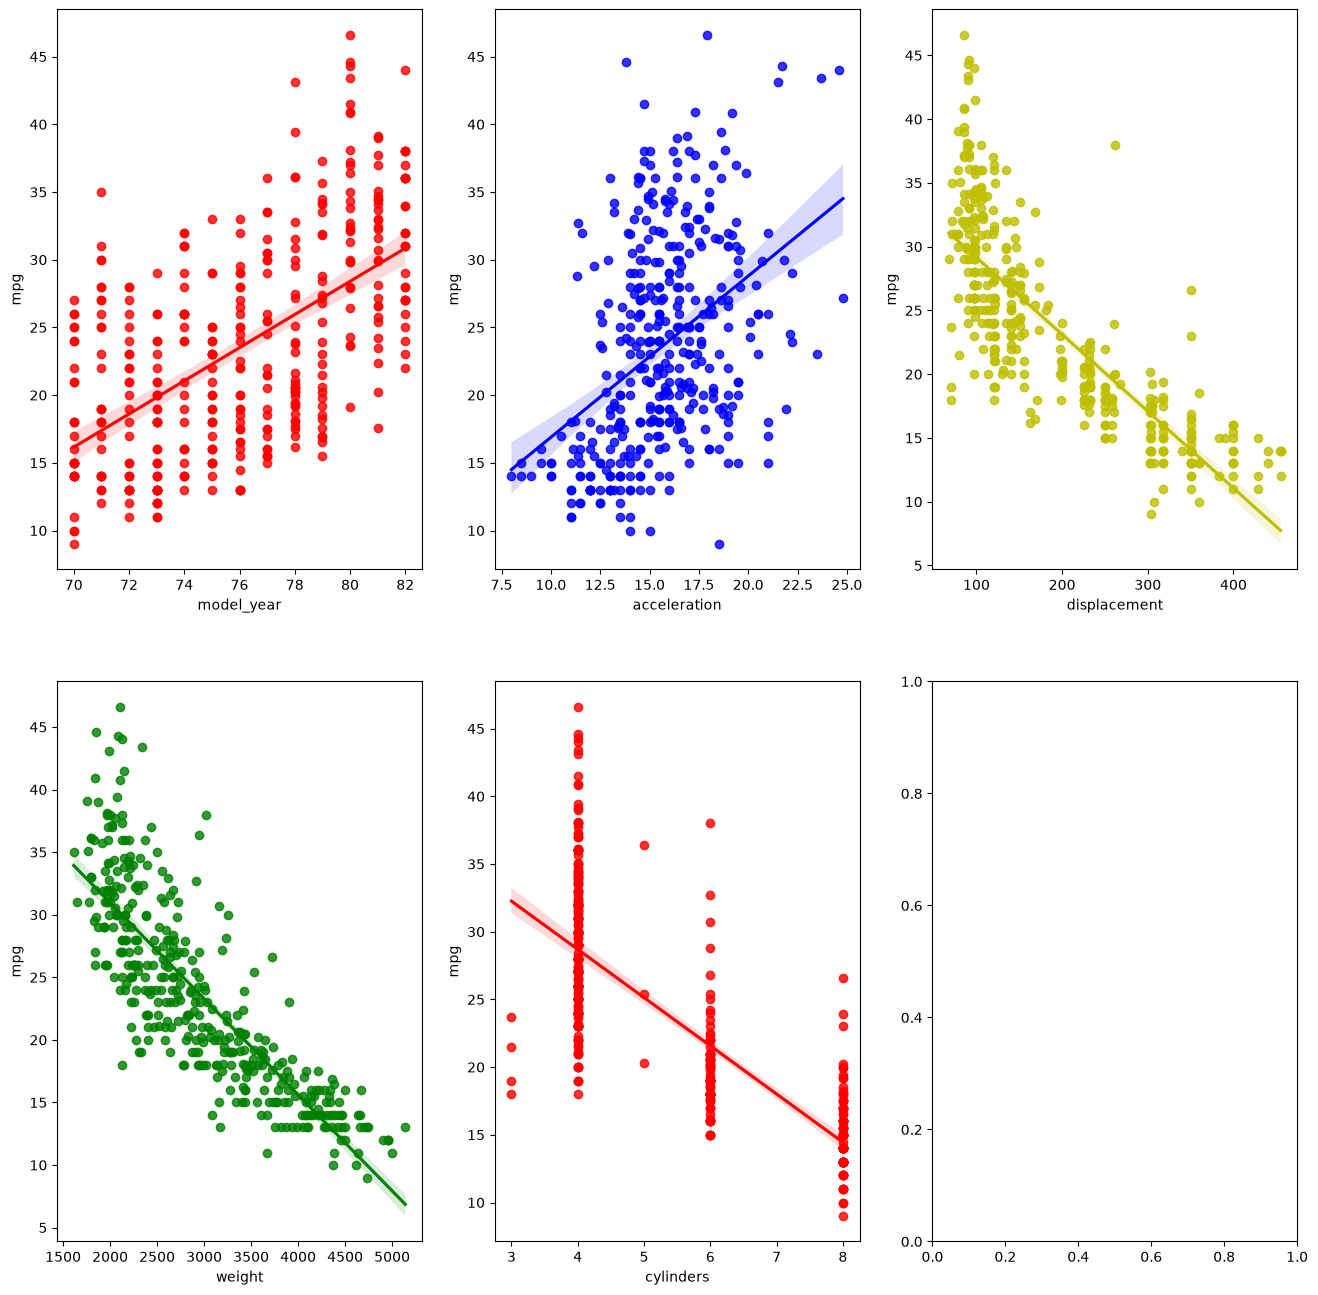

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(figsize = (16, 16), ncols = 3, nrows = 2) # 2행 3열
x_features = ['model_year', 'acceleration', 'displacement', 'weight', 'cylinders']
plot_color = ['r', 'b', 'y', 'g', 'r']
for i, feature in enumerate(x_features):
    row = int(i/3)
    col = i%3
    sns.regplot(x = feature, y = 'mpg', data = naive_df, ax = axs[row][col], color = plot_color[i])
plt.show()

In [35]:
# 학습 sol2. with RobustScaler
from sklearn.preprocessing import RobustScaler

# 스케일러 객체 생성
scaler = RobustScaler()

# 학습 데이터를 기준으로 스케일링 파라미터 계산(fit) 및 변환(transform)
x_train_robust = scaler.fit_transform(X_train)

# 테스트 데이터는 변환(transform)만 수행
x_test_robust = scaler.transform(X_test)

print('x_train type: {0}, x_test type: {1}'.format(type(x_train_robust), type(x_test_robust)))
print('x_train size: {0}, x_test size: {1}'.format(x_train_robust.shape, x_test_robust.shape))

x_train type: <class 'numpy.ndarray'>, x_test type: <class 'numpy.ndarray'>
x_train size: (278, 5), x_test size: (120, 5)


In [38]:
lr2 = LinearRegression()
lr2.fit(x_train_robust, Y_train)

Y_predict2 = lr2.predict(x_test_robust)

temp_df2 = pd.DataFrame(x_test_robust.copy(), index=X_test.index, columns=X.columns)

print('temp_df2 type: {0}'.format(type(temp_df2)))
print('temp_df2 size: {0}'.format(temp_df2.shape))

print('sizeof Y_test: {0}, sizeof Y_predict2: {1}'.format(Y_test.shape, Y_predict2.shape))

temp_df2['MPG'] = Y_test
temp_df2['Y_HAT'] = Y_predict2

display(temp_df2.head())

temp_df2 type: <class 'pandas.DataFrame'>
temp_df2 size: (120, 5)
sizeof Y_test: (120,), sizeof Y_predict2: (120,)


,cylinders,displacement,weight,acceleration,model_year,MPG,Y_HAT
65,1.0,1.244168,0.937397,-0.833333,-0.666667,14.0,12.688139
132,0.0,-0.068429,-0.221208,0.500000,-0.333333,25.0,24.892357
74,1.0,0.939347,1.057857,0.166667,-0.666667,13.0,11.779662
78,0.0,-0.192846,0.097828,1.333333,-0.666667,21.0,20.713484
37,0.5,0.503888,0.323417,0.000000,-0.833333,18.0,17.599750


In [40]:
mse2 = mean_squared_error(Y_test, Y_predict2)
rmse2 = np.sqrt(mse2)
print('MSE: {0:.3f}, RMSE: {1:.3f}'.format(mse2, rmse2))
print('R^2(Variance score): {0:.3f}'.format(r2_score(Y_test, Y_predict2)))

MSE: 12.278, RMSE: 3.504
R^2(Variance score): 0.808


In [41]:
print('Y 절편 값: ', np.round(lr2.intercept_, 2))
print('회귀 계수 값: ', np.round(lr2.coef_, 2))

Y 절편 값:  24.11
회귀 계수 값:  [-0.55  1.2  -9.43  0.59  4.55]


In [42]:
coef = pd.Series(data = np.round(lr2.coef_, 2), index = X.columns)
coef.sort_values(ascending = False)

model_year      4.55
displacement    1.20
acceleration    0.59
cylinders      -0.55
weight         -9.43
dtype: float64

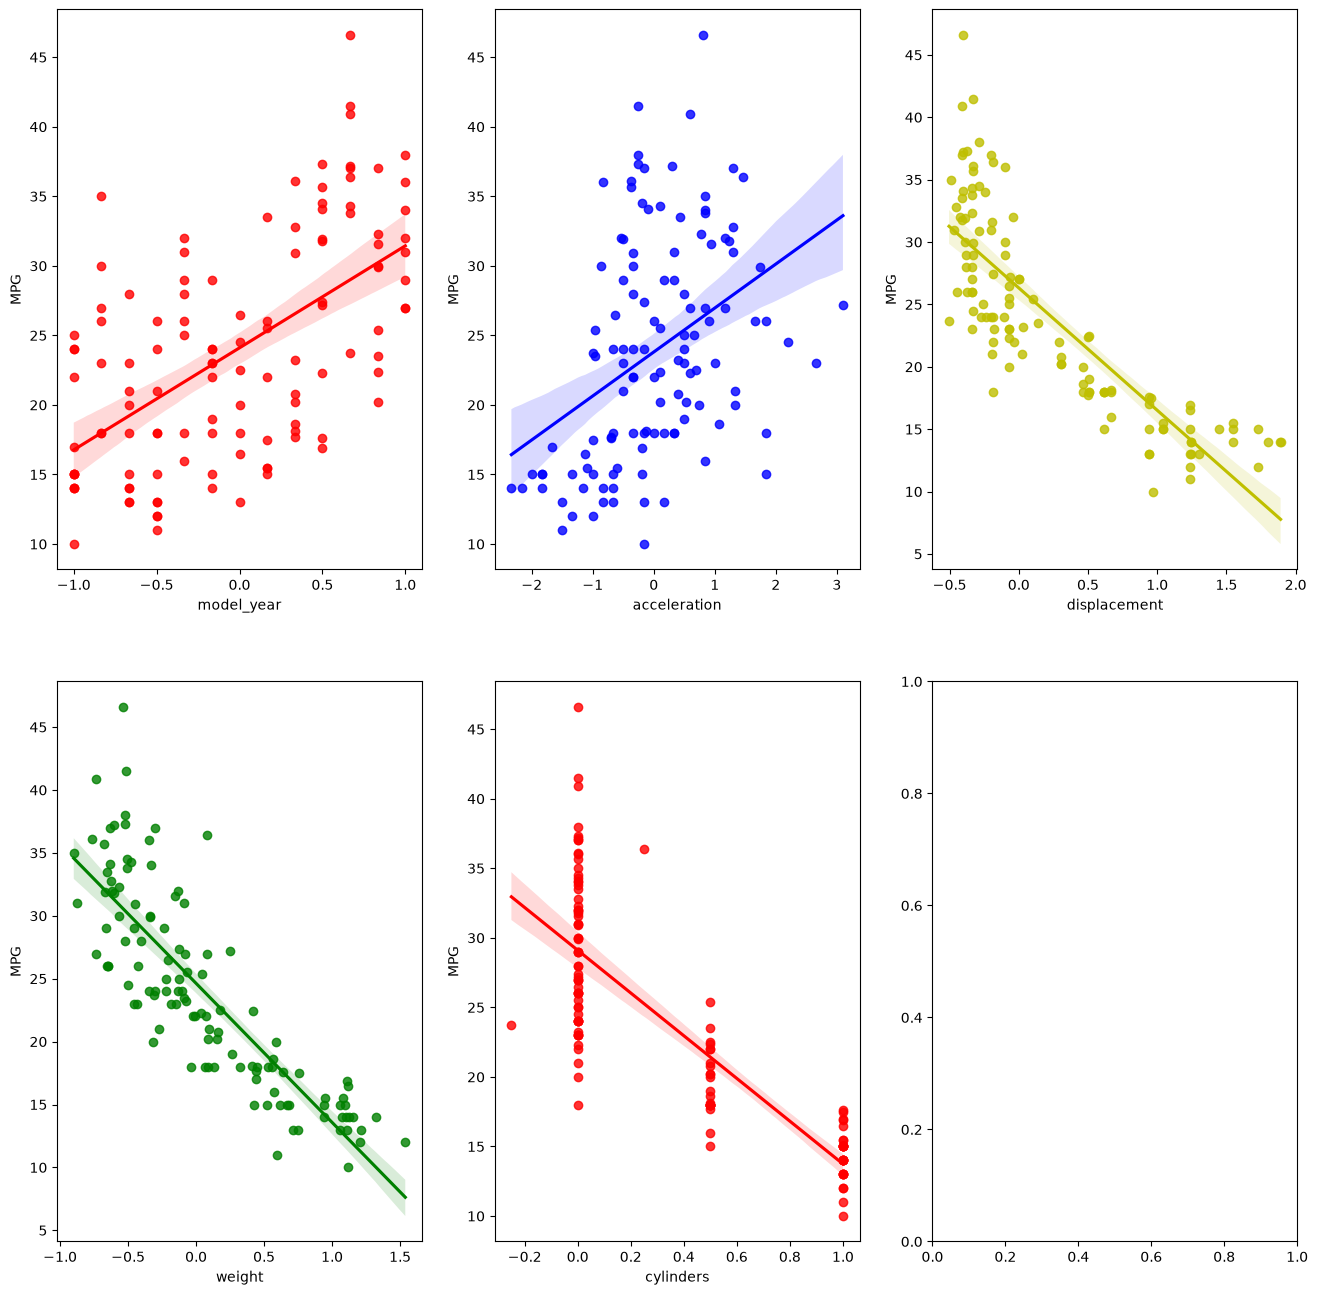

In [45]:
fig, axs = plt.subplots(figsize = (16, 16), ncols = 3, nrows = 2)
x_features = ['model_year', 'acceleration', 'displacement', 'weight', 'cylinders']
plot_color = ['r', 'b', 'y', 'g', 'r']
for i, feature in enumerate(x_features):
    row = int(i/3)
    col = i%3
    sns.regplot(x = feature, y = 'MPG', data = temp_df2, ax = axs[row][col], color = plot_color[i])
plt.show()